In [1]:
import sys; sys.path.append("..")
import warnings, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
from src.features import get_splits
from src.evaluation import make_cv
from src.nn import cv_nn, fit_nn

X_train, X_test, y_train, y_test = get_splits("../data/raw/telco_churn.csv")

In [2]:
configs = {"weaker reg (l2=1e-3, dropout=0.3)": {"l2": 1e-3, "dropout": 0.3},
           "stronger reg (l2=1e-2, dropout=0.5)": {"l2": 1e-2, "dropout": 0.5}}
summary = []
for name, kw in configs.items():
    r = pd.DataFrame(cv_nn(X_train, y_train, make_cv(), **kw))
    print(name); print(r.round(4).to_string(index=False), "\n")
    summary.append({"model": f"NN {name}", "train_AUC": r.train_auc.mean(),
                    "CV_AUC": r.auc.mean(), "CV_AUC_std": r.auc.std(),
                    "CV_PR_AUC": r.pr_auc.mean(), "CV_PR_std": r.pr_auc.std()})
nn_table = pd.DataFrame(summary).round(4); nn_table

weaker reg (l2=1e-3, dropout=0.3)
 train_auc    auc  pr_auc  epochs
    0.8607 0.8436  0.6395      53
    0.8648 0.8283  0.6454      56
    0.8693 0.8385  0.6784      82
    0.8573 0.8617  0.6806      57
    0.8662 0.8489  0.6498      80 

stronger reg (l2=1e-2, dropout=0.5)
 train_auc    auc  pr_auc  epochs
    0.8517 0.8459  0.6491      85
    0.8550 0.8294  0.6469      74
    0.8523 0.8431  0.6823      70
    0.8469 0.8621  0.6765      57
    0.8500 0.8525  0.6554     126 



,model,train_AUC,CV_AUC,CV_AUC_std,CV_PR_AUC,CV_PR_std
0,"NN weaker reg (l2=1e-3, dropout=0.3)",0.8636,0.8442,0.0124,0.6587,0.0193
1,"NN stronger reg (l2=1e-2, dropout=0.5)",0.8512,0.8466,0.0121,0.6620,0.0163


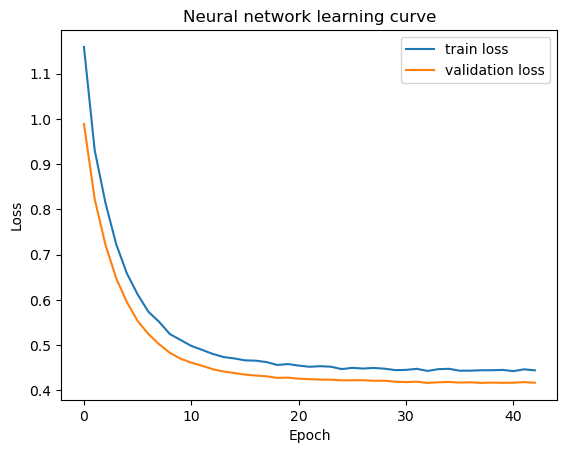

In [3]:
_, _, hist = fit_nn(X_train, y_train, l2=1e-2, dropout=0.5)
plt.plot(hist.history["loss"], label="train loss")
plt.plot(hist.history["val_loss"], label="validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
plt.title("Neural network learning curve")
plt.savefig("../reports/figures/nn_learning_curve.png", dpi=150, bbox_inches="tight")
plt.show()